In [24]:
import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

In [ ]:
from generate_f_from_white_noise import *
import time
import heat1D_crank_nicolson_solver as cns
import h5py

np.random.seed(42)

#----------------------------------------------------------------------------

type_used = np.float32

# Parametri simulazione
L = 1
Tf = 10
nt = 5000
D = 1
wanted_r = 0.8
h = 1

solver = cns.Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

#----------------------------------------------------------------------------

# Di default viene salvata f che corrisponde a nx=0
impulses_indexes = np.array([solver.nx // 2, solver.nx - 1], dtype=np.uint64)

N_impulses = np.size(impulses_indexes)

# Numero di samples
N_f = 30000

lista_f = np.empty((N_f, nt), dtype=type_used)

# Calcolo risorse necessarie
memory_required_bytes = lista_f.nbytes * (N_impulses + 1)

print(f"\n---------- Dataset info")
print(f"Number of samples:          {N_f}")
print(f"Sample size:                {nt}")
print(f"Number of impulses:         {N_impulses}")

for imp in impulses_indexes:
    print(f"    - Impulse at nx = {imp + 1}")

print(f"Total memory required:      {int(memory_required_bytes/(1024**2))} MB")

#----------------------------------------------------------------------------
print(f"\n---------- Computing impulse responses")
start = time.time()

lista_trasformata_impulsi = np.empty((N_impulses, nt), dtype=np.complex128)

# Trasformata di fourier della risposta all'impulso
n = (2*nt - 1)

# Definisci impulso
impulse = np.zeros(nt)

impulse[0] = 1/solver.dt

# Risolvi evoluzione completa per impulso
T = solver.solve(impulse)

for i in range(N_impulses):
    g = T[impulses_indexes[i],:]

    # Note: np.fft.rfft sfrutta la simmetria dell'input per restituire un vettore di lunghezza
    # n//2 + 1 che nel nostro caso diventa proprio (2*nt - 1)//2 + 1 = nt
    lista_trasformata_impulsi[i] = np.fft.rfft(g, n)

end = time.time()
print(f"Impulse responses computed. Time taken:         {(end - start):.3f} sec")

#----------------------------------------------------------------------------

print(f"\n---------- Generating left boundary conditions f")
start = time.time()

min_freq = 1/(solver.t_array[-1]-solver.t_array[1])

for i in range(N_f):
    sigma_filter = np.random.uniform(3,7)*min_freq
    gaussian_filter = lambda k : np.exp(-(k**2)/(2*sigma_filter**2))
    lista_f[i] = generate_random_f_from_white_noise(solver.t_array, gaussian_filter)

end = time.time()
print(f"Boundary conditions generated. Time taken:      {(end - start):.3f} sec")

#----------------------------------------------------------------------------

print(f"\n---------- Performing convolutions")
start = time.time()

dataset = np.empty((N_f, N_impulses+1, nt), dtype=type_used)

# Calcola la trasformata di tutte le f
# Correzione derivante dalla regola dei trapezi usata in nicolson e dalla definizione della convoluzione
f_trap = (lista_f + np.roll(lista_f, -1, axis=1))
f_trap[:, -1] = lista_f[:, -1]  # ultimo elemento: solo f[N-1] (f[N]=0)
lista_F = np.fft.rfft(f_trap, n, axis=1)

#lista_F = np.fft.rfft(lista_f, n, axis=1)

'''
for i, f in enumerate(lista_f):
    dataset[i,0] = f
    for j, G in enumerate(lista_trasformata_impulsi):
        dataset[i,j+1] = np.fft.irfft(lista_F[i] * G, n)[:nt] * solver.dt

'''

for i in range(N_f):
    dataset[i,0] = lista_f[i]
    dataset[i,1:] = np.fft.irfft(
        lista_F[i][None, :] * lista_trasformata_impulsi,
        n,
        axis=1
    )[:, :nt] * solver.dt


end = time.time()
print(f"Convolution finished. Time taken:               {(end - start):.3f} sec")
print(f"Average time per sample:                        {(end - start)/N_f:.3f} sec")

print(f"\n---------- Saving Dataset")
#print(f"Dataset size: {dataset.nbytes / (1024**2):.2f} MB")
start = time.time()

with h5py.File("dataset/dataset.h5", "w") as save_file:
    save_file.create_dataset("dataset", data=dataset)

end = time.time()
print(f"Dataset saved. Time taken:                      {(end - start):.3f} sec")

---------- Solver info
Time scale coeff:       1.00e+00
dx:                     5.00e-02
dt:                     2.00e-03
nt:                     5000
nx:                     21
r:                      8.00e-01

---------- Dataset info
Number of samples:          30000
Sample size:                5000
Number of impulses:         2
    - Impulse at nx = 11
    - Impulse at nx = 21
Total memory required:      1716 MB

---------- Computing impulse responses
Impulse responses computed. Time taken:         0.038 sec

---------- Generating left boundary conditions f
Boundary conditions generated. Time taken:      8.163 sec

---------- Performing convolutions
Convolution finished. Time taken:               12.450 sec
Average time per sample:                        0.000 sec

---------- Saving Dataset


Squared distance: 1.8281837064629294e-14
Squared distance: 1.4476034890061147e-14


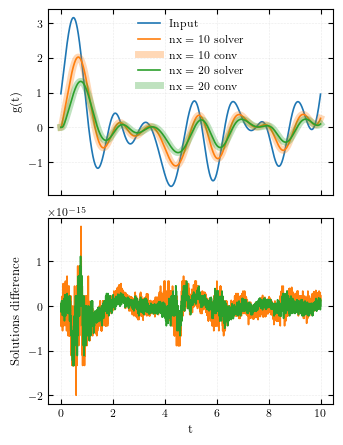

In [ ]:
# Verifica funzionamento
fig, axes = plt.subplots(2,1,figsize=(3.4, 4.4), sharex=True)
fig.tight_layout()

f_test = dataset[0,0]
T = solver.solve(f_test)
axes[0].plot(solver.t_array,f_test,label="Input", color="C0")
for i in range(N_impulses):
    g_solver_tmp = T[impulses_indexes[i], :]
    axes[0].plot(solver.t_array, g_solver_tmp, color=f"C{i+1}", label=f"nx = {impulses_indexes[i]} solver")
    axes[0].plot(solver.t_array, dataset[0,i+1], lw=5,alpha=0.3, color=f"C{i+1}", label=f"nx = {impulses_indexes[i]} conv")
    axes[0].legend()

    print(f"Squared distance: {np.linalg.norm(dataset[0,i+1,:]-g_solver_tmp[:])}")
    axes[1].plot(solver.t_array,(dataset[0,i+1,:]-g_solver_tmp[:]), color=f"C{i+1}")
    axes[1].set_ylabel("Solutions difference")
    
axes[0].grid()
axes[1].grid()
axes[1].set_xlabel("t")
axes[0].set_ylabel("g(t)")

plt.show()